In [ ]:
import sys, os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


try:
    from dtaidistance import dtw
except ImportError:
    if "google.colab" in sys.modules:
        os.system("pip install -q dtaidistance")
    else:
        os.system("pip install -q dtaidistance --break-system-packages")
    from dtaidistance import dtw

from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.manifold import MDS

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Ready.")

Ready.


In [ ]:
if "google.colab" in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    FILENAME = list(uploaded.keys())[0]
else:
    FILENAME = "ftse250_clustering_ready.csv"
print("Using file:", FILENAME)

Saving ftse250_clustering_ready (1).csv to ftse250_clustering_ready (1).csv
Using file: ftse250_clustering_ready (1).csv


In [ ]:

MAX_MISSING_FRAC = 0.10

df = pd.read_csv(FILENAME)
date_cols = [c for c in df.columns if c != "Ticker"]

frac = df[date_cols].isna().sum(axis=1) / len(date_cols)
dropped = df.loc[frac > MAX_MISSING_FRAC, "Ticker"].tolist()
df = df.loc[frac <= MAX_MISSING_FRAC].reset_index(drop=True)

n_filled = int(df[date_cols].isna().sum().sum())
df[date_cols] = df[date_cols].ffill(axis=1).bfill(axis=1)

tickers = df["Ticker"].values
A = df[date_cols].values.astype(float)
dates = pd.to_datetime(date_cols)

print(f"Dropped (>10% missing) : {len(dropped)} {dropped}")
print(f"Single gaps filled     : {n_filled}")
print(f"Stocks retained        : {len(df)}")
print(f"Trading days            : {len(date_cols)}")
print(f"Date range              : {date_cols[0]} to {date_cols[-1]}")
assert df[date_cols].isna().sum().sum() == 0

Dropped (>10% missing) : 0 []
Single gaps filled     : 4
Stocks retained        : 241
Trading days            : 1153
Date range              : 2021-11-30 to 2026-06-29


In [ ]:
t0 = time.time()


A_dtw = A
T = A.shape[1]
WINDOW_FRAC = 0.05
WINDOW = int(WINDOW_FRAC * T)


D = dtw.distance_matrix_fast(A_dtw, window=WINDOW)
D = np.maximum(D, D.T)
np.fill_diagonal(D, 0.0)

print(f"DTW distance matrix computed in {time.time()-t0:.1f}s")
print(f"Series length: {T}, window: {WINDOW} days")
print(f"Distance matrix shape: {D.shape}")
print(f"Distance range: [{D.min():.3f}, {D.max():.3f}], mean {D[D>0].mean():.3f}")

DTW distance matrix computed in 31.2s
Series length: 1153, window: 57 days
Distance matrix shape: (241, 241)
Distance range: [0.000, 66.452], mean 34.979


In [ ]:

K_RANGE = range(2, 11)
N_SUBSAMPLES = 100
SUBSAMPLE_FRAC = 0.8

_CM_CACHE = {}


def _pam_build_init(D, k):

    n = D.shape[0]
    medoids = [int(np.argmin(D.sum(axis=1)))]
    nearest = D[:, medoids[0]].copy()
    for _ in range(1, k):

        gain = np.maximum(nearest[:, None] - D, 0.0).sum(axis=0)
        gain[medoids] = -np.inf
        j = int(np.argmax(gain))
        medoids.append(j)
        nearest = np.minimum(nearest, D[:, j])
    return np.array(medoids)


def _pam_swap(D, medoids, max_iter):

    n = D.shape[0]
    k = len(medoids)
    medoids = medoids.copy()
    for _ in range(max_iter):
        Dm = D[:, medoids]
        order = np.argsort(Dm, axis=1)
        nearest_idx = order[:, 0]
        d1 = Dm[np.arange(n), nearest_idx]
        d2 = (Dm[np.arange(n), order[:, 1]] if k > 1
              else np.full(n, np.inf))
        cur_cost = d1.sum()

        best_cost, best_i, best_h = cur_cost, -1, -1
        for i in range(k):

            d_wo = np.where(nearest_idx == i, d2, d1)

            swap_cost = np.minimum(D, d_wo[:, None]).sum(axis=0)
            swap_cost[medoids] = np.inf
            h = int(np.argmin(swap_cost))
            if swap_cost[h] < best_cost - 1e-12:
                best_cost, best_i, best_h = swap_cost[h], i, h

        if best_i < 0:
            break
        medoids[best_i] = best_h
    return medoids


def kmedoids_pam(D, k, n_init=10, max_iter=100, random_state=RANDOM_STATE):

    n = D.shape[0]
    medoids = _pam_build_init(D, k)
    medoids = _pam_swap(D, medoids, max_iter)
    labels = np.argmin(D[:, medoids], axis=1)
    cost = D[np.arange(n), medoids[labels]].sum()
    return medoids, labels, cost

def calinski_harabasz_distmat(D, labels):

    D2 = np.asarray(D, dtype=float) ** 2
    n = D2.shape[0]
    clusters = np.unique(labels)
    k = len(clusters)
    if k < 2 or k >= n:
        return np.nan
    ss_total = D2.sum() / (2 * n)
    ss_within = 0.0
    for c in clusters:
        idx = np.where(labels == c)[0]
        ss_within += D2[np.ix_(idx, idx)].sum() / (2 * len(idx))
    ss_between = ss_total - ss_within
    if ss_within <= 0:
        return np.nan
    return (ss_between / (k - 1)) / (ss_within / (n - k))



def dunn_index(D, labels):

    clusters = np.unique(labels)
    intra_max = 0.0
    for c in clusters:
        idx = np.where(labels == c)[0]
        if len(idx) > 1:
            intra_max = max(intra_max, D[np.ix_(idx, idx)].max())
    inter_min = np.inf
    for i, ci in enumerate(clusters):
        for cj in clusters[i + 1:]:
            idx_i = np.where(labels == ci)[0]
            idx_j = np.where(labels == cj)[0]
            inter_min = min(inter_min, D[np.ix_(idx_i, idx_j)].min())
    return inter_min / intra_max if intra_max > 0 else np.nan


def davies_bouldin_distmat(D, labels, medoids):

    k = len(medoids)
    S = np.array([D[np.where(labels == ci)[0], medoids[ci]].mean() for ci in range(k)])
    total = 0.0
    for ci in range(k):
        best = 0.0
        for cj in range(k):
            if ci == cj:
                continue
            d_ij = D[medoids[ci], medoids[cj]]
            ratio = (S[ci] + S[cj]) / d_ij if d_ij > 0 else np.inf
            best = max(best, ratio)
        total += best
    return total / k


def consensus_matrix(D, k, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC,
                     n_init=3, seed=RANDOM_STATE):

    key = (D.shape, hash(D.tobytes()), k, B, frac, n_init, seed)
    if key in _CM_CACHE:
        return _CM_CACHE[key]

    rng = np.random.default_rng(seed)
    n = D.shape[0]
    m = int(frac * n)

    together = np.zeros((n, n))
    sampled = np.zeros((n, n))
    for b in range(B):
        idx = rng.choice(n, m, replace=False)
        _, lab, _ = kmedoids_pam(D[np.ix_(idx, idx)], k, n_init=n_init, random_state=seed + b)
        ix = np.ix_(idx, idx)
        together[ix] += (lab[:, None] == lab[None, :])
        sampled[ix] += 1

    M = np.divide(together, sampled, out=np.zeros((n, n)), where=sampled > 0)
    np.fill_diagonal(M, 1.0)
    _CM_CACHE[key] = M
    return M


def cluster_consensus(M, labels):

    out = []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        if len(idx) < 2:
            out.append(np.nan)
            continue
        sub = M[np.ix_(idx, idx)]
        out.append(sub[np.triu_indices(len(idx), 1)].mean())
    return np.array(out)


def subsample_stability_dm(D, k, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC,
                           n_init=3, seed=RANDOM_STATE, labels=None):

    M = consensus_matrix(D, k, B=B, frac=frac, n_init=n_init, seed=seed)
    if labels is None:
        _, labels, _ = kmedoids_pam(D, k, n_init=10, random_state=seed)
    mk = cluster_consensus(M, labels)
    if np.all(np.isnan(mk)):
        return np.nan, np.nan
    return float(np.nanmean(mk)), float(np.nanmin(mk))


print("Functions defined.")

Functions defined.


In [ ]:
t0 = time.time()
n = D.shape[0]
rows = []
for k in K_RANGE:
    medoids_k, labels_k, cost_k = kmedoids_pam(D, k, n_init=10)
    consensus_matrix(D, k)       # builds + caches M, reused by the heat map / CDF / table cells below
    rows.append({
        "k": k,
        # sample_size caps the O(n^2) silhouette cost on large datasets
        "silhouette": silhouette_score(D, labels_k, metric="precomputed",
                                       sample_size=min(n, 5000), random_state=RANDOM_STATE),
        "dunn": dunn_index(D, labels_k),
        "davies_bouldin": davies_bouldin_distmat(D, labels_k, medoids_k),
        "calinski_harabasz": calinski_harabasz_distmat(D, labels_k),
    })

metrics = pd.DataFrame(rows)

print(f"Computed in {time.time()-t0:.0f}s")
print(f"Dunn index alone picks k = {int(metrics.loc[metrics['dunn'].idxmax(), 'k'])}\n")
display(metrics.round(4))

Computed in 5s
Dunn index alone picks k = 5



,k,silhouette,dunn,davies_bouldin,calinski_harabasz
0,2,0.4140,0.1094,0.6926,219.8731
1,3,0.3383,0.1077,1.2474,158.8821
2,4,0.3133,0.0940,1.1681,151.0355
3,5,0.3036,0.1095,1.4356,131.3885
4,6,0.2396,0.0815,1.5668,121.6440
5,7,0.2209,0.0831,1.5086,111.3301
6,8,0.1803,0.0739,1.5804,101.7463
7,9,0.1734,0.0738,1.6502,97.1374
8,10,0.1501,0.0738,1.6875,88.0639


In [ ]:

RANK_METRICS = {
    "silhouette": False,
    "dunn": False,
    "calinski_harabasz": False,
    "davies_bouldin": True,
}

ranked = metrics.copy()
for col, lower_is_better in RANK_METRICS.items():
    ranked[f"r_{col}"] = ranked[col].rank(ascending=lower_is_better)
ranked["mean_rank"] = ranked[[f"r_{c}" for c in RANK_METRICS]].mean(axis=1)


best = ranked.sort_values(["mean_rank", "k"]).iloc[0]
consensus_k = int(best["k"])


metrics = metrics.drop(columns=[c for c in metrics.columns
                                if c.startswith("r_") or c == "mean_rank"])
metrics = metrics.join(ranked[[f"r_{c}" for c in RANK_METRICS] + ["mean_rank"]])


lab_best = kmedoids_pam(D, consensus_k, n_init=10)[1]
mk_best = cluster_consensus(consensus_matrix(D, consensus_k), lab_best)
sizes_best = np.bincount(lab_best, minlength=consensus_k)

print(f"Silhouette alone would pick k = {int(metrics.loc[metrics['silhouette'].idxmax(), 'k'])}")
print(f"Dunn Index alone would pick   k = {int(metrics.loc[metrics['dunn'].idxmax(), 'k'])}")
print(f"Consensus of {len(RANK_METRICS)} metrics   k = {consensus_k}")
print(f"\nMean cluster consensus at consensus k : {np.nanmean(mk_best):.3f}")
print(f"Smallest cluster at consensus k       : {int(sizes_best.min())} "
      f"({100 * sizes_best.min() / len(lab_best):.1f}%)")

Silhouette alone would pick k = 2
Dunn Index alone would pick   k = 5
Consensus of 4 metrics   k = 2

Mean cluster consensus at consensus k : 0.977
Smallest cluster at consensus k       : 103 (42.7%)


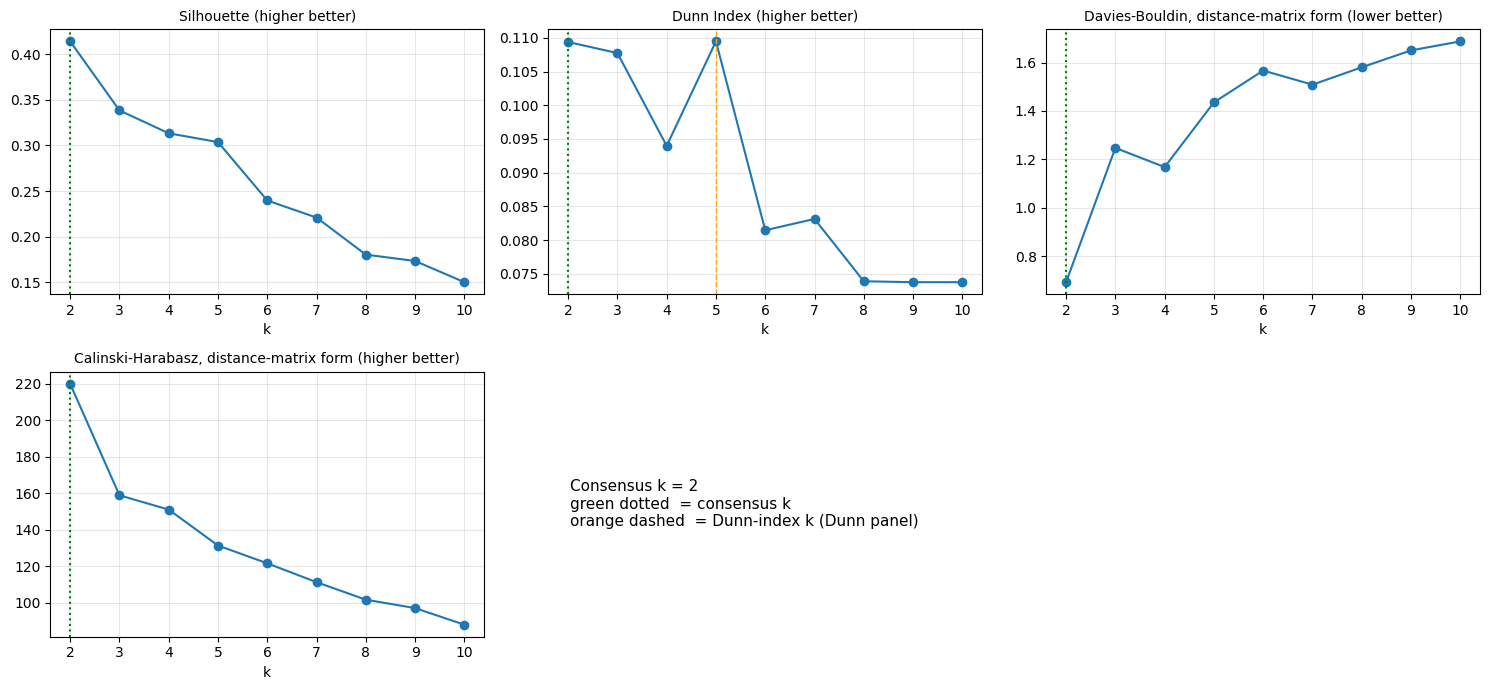

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
specs = [("silhouette", "Silhouette (higher better)"),
         ("dunn", "Dunn Index (higher better)"),
         ("davies_bouldin", "Davies-Bouldin, distance-matrix form (lower better)"),
         ("calinski_harabasz", "Calinski-Harabasz, distance-matrix form (higher better)")]

ks = metrics["k"]
dunn_k = int(metrics.loc[metrics["dunn"].idxmax(), "k"])

for ax, (col, title) in zip(axes.flat, specs):
    ax.plot(ks, metrics[col], marker="o", color="C0", zorder=2)
    ax.axvline(consensus_k, color="green", ls=":", lw=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
    ax.set_xticks(ks)

    if col == "dunn":
        ax.axvline(dunn_k, color="orange", ls="--", lw=1)

info = axes.flat[4]
info.axis("off")
lines = [f"Consensus k = {consensus_k}",
         "green dotted  = consensus k",
         "orange dashed  = Dunn-index k (Dunn panel)"]
info.text(0.05, 0.5, "\n".join(lines), transform=info.transAxes,
          fontsize=11, va="center")

axes.flat[5].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
FINAL_K = consensus_k      # override manually if you prefer a different k

assert len(tickers) == D.shape[0], "tickers and D are misaligned"

medoids, labels, cost = kmedoids_pam(D, FINAL_K, n_init=20)
stab, stab_min = subsample_stability_dm(D, FINAL_K, labels=labels)
sizes = np.bincount(labels, minlength=FINAL_K)

print("=" * 50)
print(f"  DATASET     : {FILENAME}")
print(f"  Stocks      : {len(tickers)}")
print(f"  Distance    : DTW ")
print(f"  k           : {FINAL_K}")
print("-" * 50)
print(f"  Silhouette     : {silhouette_score(D, labels, metric='precomputed'):.4f}")
print(f"  Dunn Index     : {dunn_index(D, labels):.4f}")
print(f"  Davies-Bouldin : {davies_bouldin_distmat(D, labels, medoids):.4f}")
print(f"  Cluster consensus (mean) : {stab:.4f}  (least stable cluster {stab_min:.3f})")
print("-" * 50)
print(f"  Cluster sizes  : {sizes.tolist()}")
print(f"  Sizes (%)      : {[round(100 * s / len(labels), 1) for s in sizes]}")
print(f"  Medoid tickers : {list(tickers[medoids])}")
print("=" * 50)

# Ticker -> cluster table for downstream use
assignments = pd.DataFrame({"ticker": list(tickers), "cluster": labels})

  DATASET     : ftse250_clustering_ready (1).csv
  Stocks      : 241
  Distance    : DTW 
  k           : 2
--------------------------------------------------
  Silhouette     : 0.4140
  Dunn Index     : 0.1094
  Davies-Bouldin : 0.6926
  Cluster consensus (mean) : 0.9769  (least stable cluster 0.965)
--------------------------------------------------
  Cluster sizes  : [138, 103]
  Sizes (%)      : [np.float64(57.3), np.float64(42.7)]
  Medoid tickers : ['ESCT.L', 'DLN.L']


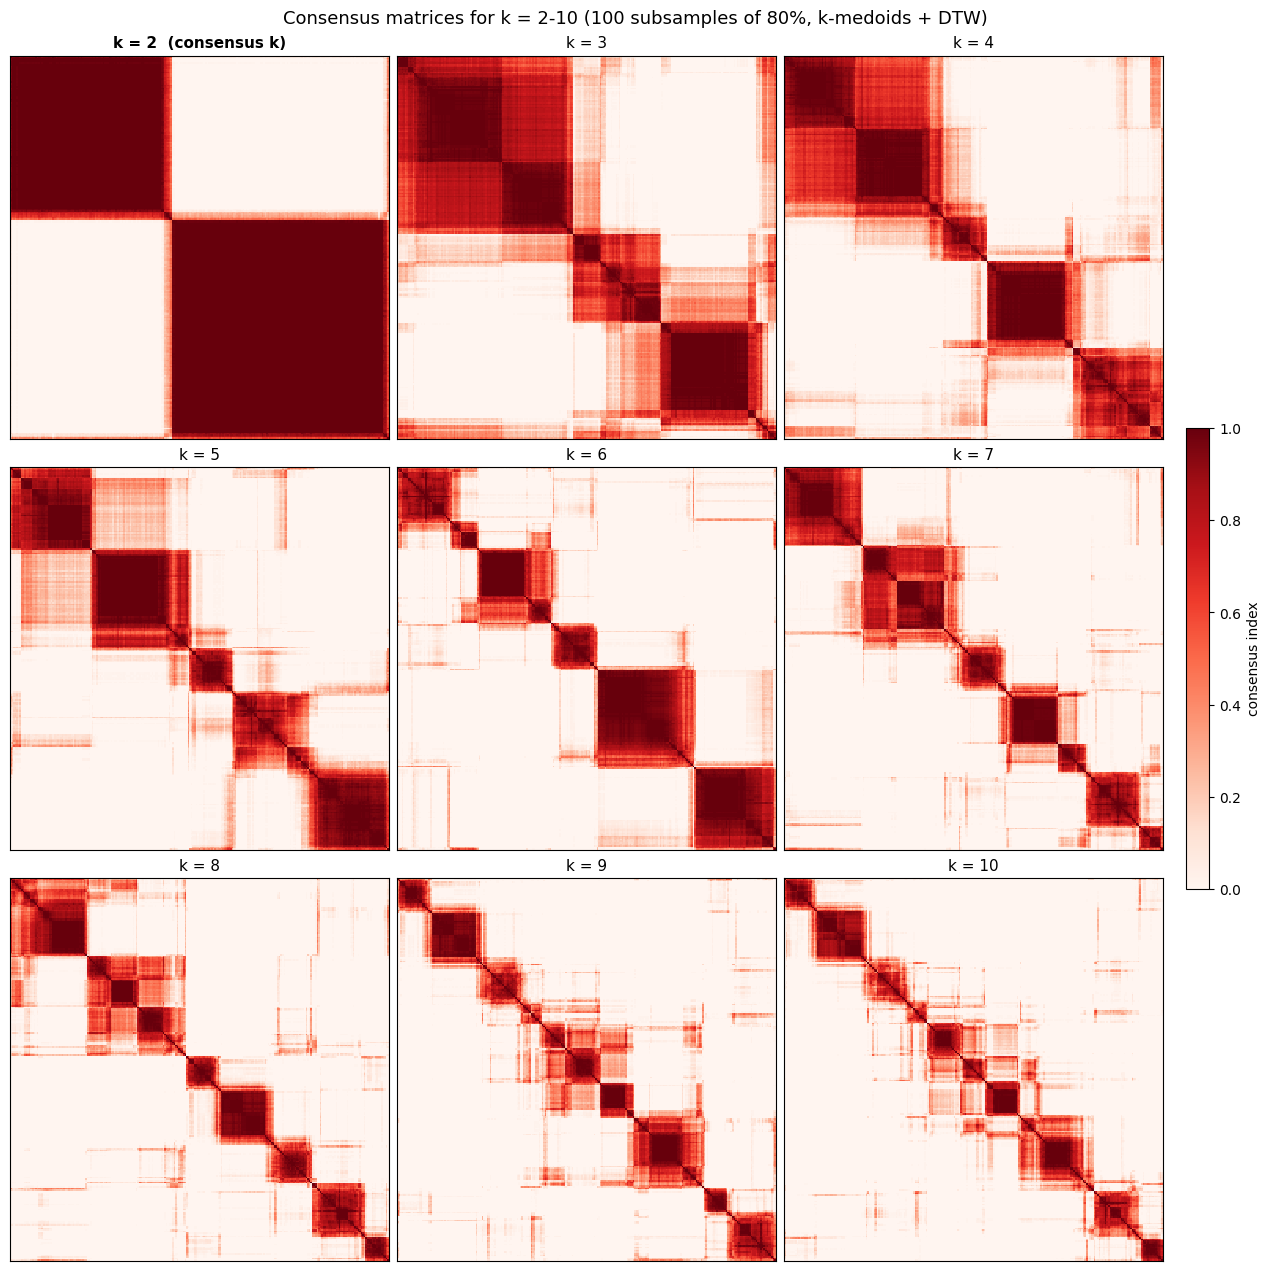

In [ ]:

from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform

ks_all = list(K_RANGE)
ncols = 3
nrows = int(np.ceil(len(ks_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), squeeze=False,
                         constrained_layout=True)

for ax, k in zip(axes.flat, ks_all):
    Mk = consensus_matrix(D, k)
    Dk = squareform(1 - Mk, checks=False)
    order_k = leaves_list(optimal_leaf_ordering(linkage(Dk, method="average"), Dk))
    im = ax.imshow(Mk[np.ix_(order_k, order_k)], cmap="Reds", vmin=0, vmax=1,
                   interpolation="nearest", aspect="auto")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"k = {k}" + ("  (consensus k)" if k == FINAL_K else ""),
                 fontsize=11, fontweight="bold" if k == FINAL_K else "normal")
for ax in axes.flat[len(ks_all):]:
    ax.axis("off")

fig.suptitle(f"Consensus matrices for k = {ks_all[0]}-{ks_all[-1]} "
             f"({N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%}, k-medoids + DTW)", fontsize=13)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="consensus index")
plt.show()

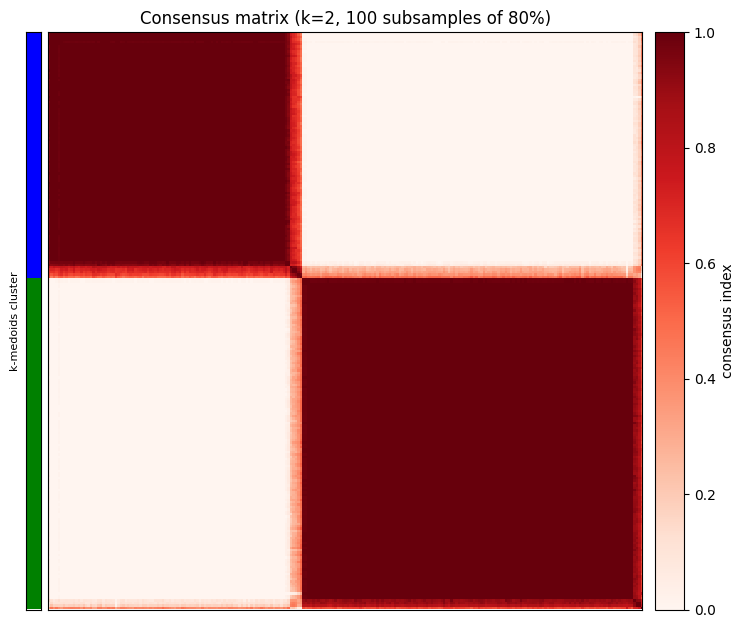

Cluster consensus m(k)  (1 = perfectly stable):
  Cluster 0 (n=138): 0.989
  Cluster 1 (n=103): 0.965


In [ ]:

from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap

M = consensus_matrix(D, FINAL_K)


Dm = squareform(1 - M, checks=False)
order = leaves_list(optimal_leaf_ordering(linkage(Dm, method="average"), Dm))

side_colors = ListedColormap(["green", "blue", "orange", "red", "purple",
                              "brown", "pink", "grey", "olive", "cyan"][:FINAL_K])

fig, (ax_bar, ax_hm) = plt.subplots(1, 2, figsize=(8.5, 7.5),
                                    gridspec_kw={"width_ratios": [1, 40], "wspace": 0.02})
im = ax_hm.imshow(M[np.ix_(order, order)], cmap="Reds", vmin=0, vmax=1,
                  interpolation="nearest", aspect="auto")
ax_bar.imshow(labels[order][:, None], cmap=side_colors, vmin=0, vmax=max(FINAL_K - 1, 1),
              interpolation="nearest", aspect="auto")
for ax in (ax_bar, ax_hm):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax_bar.set_ylabel("k-medoids cluster", fontsize=8)
ax_hm.set_title(f"Consensus matrix (k={FINAL_K}, {N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%})")
fig.colorbar(im, ax=ax_hm, fraction=0.046, pad=0.02, label="consensus index")
plt.show()

mk = cluster_consensus(M, labels)
print("Cluster consensus m(k)  (1 = perfectly stable):")
for c in range(FINAL_K):
    print(f"  Cluster {c} (n={int((labels == c).sum())}): {mk[c]:.3f}")

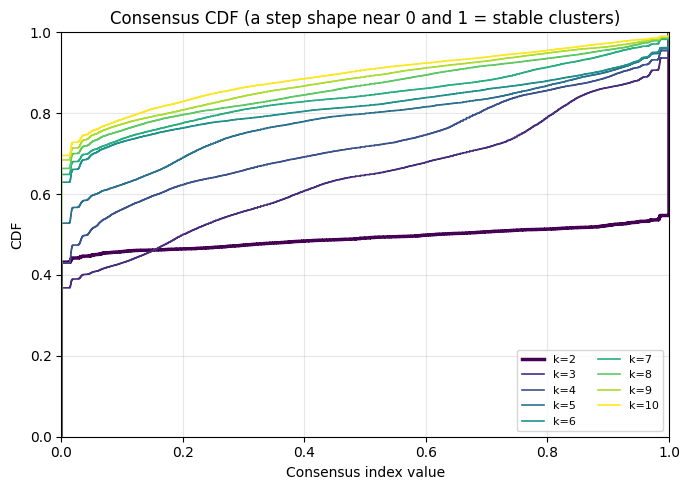

In [ ]:
# Consensus CDF for every k (Monti et al., 2003, Eq. 5; Leal et al., 2025, Fig. 9)
fig, ax = plt.subplots(figsize=(7, 5))
colors = plt.get_cmap("viridis", len(K_RANGE))

for i, k in enumerate(K_RANGE):
    Mk = consensus_matrix(D, k)                       # cached from the metrics loop
    vals = np.sort(Mk[np.triu_indices(Mk.shape[0], 1)])   # the N(N-1)/2 entries with i < j
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, cdf, where="post", color=colors(i),
            lw=2.5 if k == FINAL_K else 1.2, label=f"k={k}")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Consensus index value")
ax.set_ylabel("CDF")
ax.set_title("Consensus CDF (a step shape near 0 and 1 = stable clusters)")
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

In [ ]:

cc_rows, size_rows = {}, {}
for k in K_RANGE:
    Mk = consensus_matrix(D, k)
    lab_k = kmedoids_pam(D, k, n_init=10)[1]
    cc_rows[k] = cluster_consensus(Mk, lab_k)
    size_rows[k] = np.bincount(lab_k, minlength=k)

cols = [f"Cluster {c}" for c in range(max(K_RANGE))]
cluster_consensus_table = pd.DataFrame(
    [list(v) + [np.nan] * (len(cols) - len(v)) for v in cc_rows.values()],
    index=pd.Index(list(cc_rows), name="k"), columns=cols)
cluster_size_table = pd.DataFrame(
    [list(v) + [np.nan] * (len(cols) - len(v)) for v in size_rows.values()],
    index=pd.Index(list(size_rows), name="k"), columns=cols)
print("Cluster consensus (1 = perfectly stable; blank = no such cluster at this k)")
display(cluster_consensus_table.round(3).style.format("{:.3f}", na_rep="")
        .background_gradient(cmap="Reds", vmin=0, vmax=1, subset=cols))
print("Cluster sizes (number of stocks)")
display(cluster_size_table.style.format("{:.0f}", na_rep=""))

Cluster consensus (1 = perfectly stable; blank = no such cluster at this k)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9
k,,,,,,,,,,
2,0.989,0.965,,,,,,,,
3,0.713,0.832,0.842,,,,,,,
4,0.677,0.893,0.812,0.716,,,,,,
5,0.642,0.818,0.602,0.617,0.594,,,,,
6,0.821,0.783,0.826,0.632,0.794,0.907,,,,
7,0.749,0.886,0.726,0.730,0.786,0.819,0.796,,,
8,0.765,0.823,0.649,0.862,0.709,0.736,0.697,0.680,,
9,0.561,0.859,0.623,0.831,0.705,0.690,0.710,0.766,0.745,
10,0.565,0.700,0.567,0.819,0.601,0.583,0.638,0.729,0.843,0.755


Cluster sizes (number of stocks)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9
k,,,,,,,,,,
2,138,103,,,,,,,,
3,61,68,112,,,,,,,
4,36,55,93,57,,,,,,
5,41,51,93,20,36,,,,,
6,34,46,63,21,27,50,,,,
7,21,33,61,16,26,50,34,,,
8,21,35,39,15,23,45,36,27,,
9,15,33,34,15,24,43,31,25,21,
10,15,20,34,15,26,43,30,25,16,17


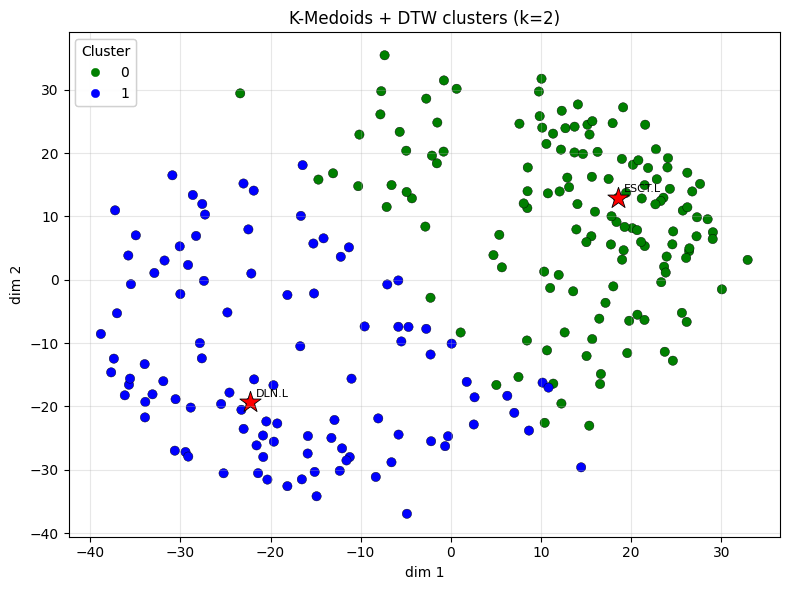

In [ ]:
from matplotlib.colors import ListedColormap


mds = MDS(n_components=2, dissimilarity="precomputed", random_state=RANDOM_STATE,
          normalized_stress=False)
V = mds.fit_transform(D)

cmap = ListedColormap(["green", "blue", "orange", "red", "purple", "brown", "pink", "grey", "olive", "cyan"][:FINAL_K])

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(V[:, 0], V[:, 1], c=labels, cmap=cmap, s=45, edgecolor="k", linewidth=0.3)
ax.scatter(V[medoids, 0], V[medoids, 1], marker="*", s=260, c="red", edgecolor="k", linewidth=0.6, label="medoids")
for m in medoids:
    ax.annotate(tickers[m], (V[m, 0], V[m, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_title(f"K-Medoids + DTW clusters (k={FINAL_K})")
ax.set_xlabel("dim 1"); ax.set_ylabel("dim 2")
ax.add_artist(ax.legend(*sc.legend_elements(), title="Cluster", loc="upper left"))
plt.tight_layout(); plt.show()

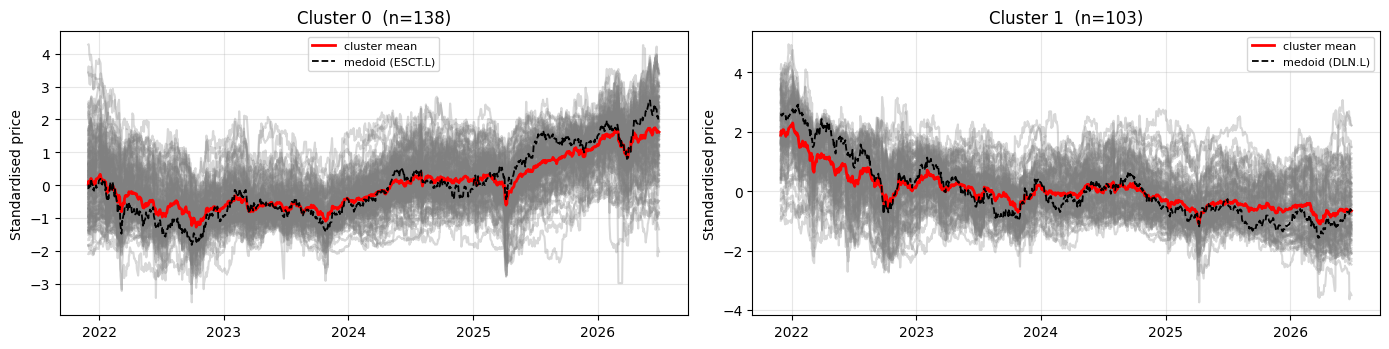

In [ ]:
n_cols = 2
n_rows = int(np.ceil(FINAL_K / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.6 * n_rows), squeeze=False)

for c in range(FINAL_K):
    ax = axes[c // n_cols][c % n_cols]
    mem = A[labels == c]
    mu = mem.mean(axis=0)
    ax.plot(dates, mem.T, color="gray", alpha=0.3)
    ax.plot(dates, mu, color="red", lw=2, label="cluster mean")
    ax.plot(dates, A[medoids[c]], color="black", lw=1.3, ls="--", label=f"medoid ({tickers[medoids[c]]})")
    ax.set_title(f"Cluster {c}  (n={len(mem)})")
    ax.set_ylabel("Standardised price")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(fontsize=8)

for c in range(FINAL_K, n_rows * n_cols):
    axes[c // n_cols][c % n_cols].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import textwrap
for c in range(FINAL_K):
    mem = sorted(tickers[labels == c])
    print(f"Cluster {c} (n={len(mem)}, medoid={tickers[medoids[c]]}):")
    labelled = [f"*{t}*" if t == tickers[medoids[c]] else t for t in mem]
    print(textwrap.fill(", ".join(labelled), width=95))
    print()

Cluster 0 (n=138, medoid=ESCT.L):
3IN.L, AAS.L, AEP.L, AGT.L, AIE.L, AJB.L, ALFA.L, AO.L, ASL.L, ATR.L, ATT.L, ATYM.L, AVON.L,
BAG.L, BBY.L, BCG.L, BGFD.L, BMY.L, BNKR.L, BOWL.L, BOY.L, BPCR.L, BRGE.L, BRWM.L, BUT.L,
CHG.L, CKN.L, CLDN.L, CMCX.L, COA.L, CORD.L, COST.L, CSN.L, CTY.L, CURY.L, CWK.L, DRX.L,
EDIN.L, ELM.L, EMG.L, *ESCT.L*, EWG.L, EWI.L, FAN.L, FCH.L, FCSS.L, FEML.L, FEV.L, FGP.L,
FOUR.L, FSG.L, FSV.L, GDWN.L, GFRD.L, GNC.L, GSCT.L, HANA.L, HGT.L, HILS.L, HMSO.L, HOC.L,
HRI.L, HTG.L, HTWS.L, HVPE.L, HWG.L, IAD.L, ICGT.L, IPF.L, JAM.L, JCH.L, JEDT.L, JEGI.L,
JEMI.L, JFJ.L, JGGI.L, JMAT.L, JMGI.L, JSG.L, JTC.L, KIE.L, KLR.L, LRE.L, LWDB.L, MAB.L,
MEGP.L, MGNS.L, MNKS.L, MNTN.L, MRC.L, MRCH.L, MTO.L, MTRO.L, MUT.L, MYI.L, OCI.L, OSB.L,
OXB.L, OXIG.L, PAF.L, PAG.L, PCGH.L, PEY.L, PFD.L, PHI.L, PIN.L, PINT.L, PLUS.L, PNL.L, POLN.L,
PPET.L, PPH.L, QLT.L, QQ.L, RAT.L, RNK.L, ROR.L, RTW.L, SAGA.L, SAIN.L, SCT.L, SDP.L, SNR.L,
SOI.L, SRP.L, TBCG.L, TCAP.L, TEM.L, TFIF.L, TMPL.L, TRS